<a id="chapter-05"></a>

# Chapter 05 · Tabular Learning and the Bellman Equation / 表格学习与 Bellman 方程

[← 学习索引](README.md) · [项目主页](../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 理解 Bellman 最优方程
- 区分 value iteration 与 Q iteration
- 实现小型 MDP 的动态规划

**开始前最好已经会：**

- 掌握第 1 章的回报递归
- 会做离散概率加权平均
- 理解 `max` 与 `argmax` 的区别


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Value, state, and optimality | 价值定义与手算 | 详细 |
| Bellman equation of optimality | 分步推导 | 详细 |
| Value of the action | V/Q 对照 | 详细 |
| Value iteration method | 算法伪代码与收敛解释 | 详细 |
| Value iteration in practice | 第一个与第二实验 | 完整 |
| Q-iteration for FrozenLake | 源码路线 | 完整 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

如果环境规则完全已知，我们能否不采集成千上万条轨迹，直接通过规则算出最优行为？这就是动态规划。

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

Bellman 方程把“整段未来”递归拆成“一步奖励 + 下一状态价值”。表格法显式保存每个状态或状态-动作对的值。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $P(s'\mid s,a)$ | 转移概率 | 动作后到达下一状态的概率 |
| $R(s,a,s')$ | 一步奖励 | 可依赖前后状态与动作 |
| $V_*(s)$ | 最优状态价值 | 从 $s$ 出发能达到的最大期望回报 |
| $Q_*(s,a)$ | 最优动作价值 | 先做 $a$，以后最优 |
| Bellman backup | 用旧价值计算新价值 | 把未来信息向前传播一步 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 固定策略时

由 $G_t=R_{t+1}+\gamma G_{t+1}$：

$$V^\pi(s)=\sum_a\pi(a|s)\sum_{s'}P(s'|s,a)[R(s,a,s')+\gamma V^\pi(s')]$$

外层平均来自策略随机选动作，内层平均来自环境随机转移。

### 2. 从固定策略到最优策略

最优价值允许在当前状态选择最好的动作，因此把策略加权平均替换为最大值：

$$\boxed{V_*(s)=\max_a\sum_{s'}P(s'|s,a)[R+\gamma V_*(s')]}$$

若把“尝试动作 $a$ 后的期望”单独命名为 $Q_*(s,a)$：

$$Q_*(s,a)=\sum_{s'}P(s'|s,a)[R+\gamma\max_{a'}Q_*(s',a')]$$

### 3. 为什么反复迭代能传播奖励

初始 $V_0=0$ 时，一次 backup 看到一步内奖励；两次看到两步内奖励。对 $\gamma<1$，Bellman optimality operator 是 contraction，误差最多乘 $\gamma$，因此有限 MDP 中会收敛到唯一不动点。


## 4. 手算一个最小例子


小环境中，状态 1 选择右动作会立即到终点并得 1，所以第一次 backup 得 $V_1(1)=1$。状态 0 选择右动作到状态 1，但旧价值还是 0，因此第一次仍为 0；第二次才得到

$$V_2(0)=0+0.9\times V_1(1)=0.9$$

这就是“奖励逐轮向前传播”。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### Bellman 最优方程

$$V_*(s)=\max_a\sum_{s'}P(s'\mid s,a)\left[R(s,a,s')+\gamma V_*(s')\right]$$

$$Q_*(s,a)=\sum_{s'}P(s'\mid s,a)\left[R(s,a,s')+\gamma\max_{a'}Q_*(s',a')\right]$$

已知模型 $P,R$ 时可反复应用 Bellman backup；未知模型时，第 6 章会改用采样更新。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $s,a$ | `reward[s, a]` | 表格的行列索引 |
| $s'$ | `next_state[s, a]` | 确定性转移；随机环境需概率加权 |
| $R+\gamma V(s')$ | `reward + gamma * V[next_state]` | 所有动作的一步 lookahead |
| $\max_a$ | `q.max(axis=1)` | 得到每个状态的最优价值 |
| $\arg\max_a$ | `q.argmax(axis=1)` | 得到贪心动作 |
| 收敛条件 | `max(abs(new_V - V)) < tol` | Bellman residual 的简化监控 |

**从公式过渡到代码时：**下面是 3 状态、2 动作的确定性 MDP。终止状态索引为 2；迭代直到最大改变量很小。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import numpy as np

# next_state[s, a] 与 reward[s, a]
next_state = np.array([[0, 1], [0, 2], [2, 2]])
reward = np.array([[0., 0.], [0., 1.], [0., 0.]])
terminal = np.array([False, False, True])
gamma = 0.9
V = np.zeros(3)

for iteration in range(100):
    q = reward + gamma * V[next_state] * (~terminal[next_state])
    new_V = q.max(axis=1)
    if np.max(np.abs(new_V - V)) < 1e-10:
        break
    V = new_V

policy = q.argmax(axis=1)
print("iterations:", iteration + 1)
print("V*:", V, "greedy actions:", policy)


iterations: 3
V*: [0.9 1.  0. ] greedy actions: [1 1 0]


### 怎样读运行结果

状态 1 的贪心动作应直达终点；状态 0 的价值约为 0.9。终止状态的未来价值必须屏蔽，否则可能重复获得不存在的奖励。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
初始化 V(s)=0
先用随机交互估计 transition counts 与 reward table
repeat:
    对每个状态 s：
对每个动作 a：
    q[a] = Σs' P_hat(s'|s,a) [R_hat + γV(s')]
V_new(s) = max_a q[a]
    V = V_new
直到 Bellman 变化足够小
执行时 action = argmax_a q[a]
```

仓库示例并非直接读取 FrozenLake 内部模型，而是用随机步估计转移概率与奖励，因此兼具 model-based 学习和动态规划。


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import numpy as np

# 随机转移的一次 Bellman expectation：动作可能到两个下一状态。
probs = np.array([0.75, 0.25])
rewards = np.array([0.0, 1.0])
next_values = np.array([2.0, 0.0])
gamma = 0.9
q_value = np.sum(probs * (rewards + gamma * next_values))
print("Q(s,a) =", q_value)
assert np.isclose(q_value, 1.6)


Q(s,a) = 1.6


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`01_frozenlake_v_iteration.py`](../Chapter05/01_frozenlake_v_iteration.py) | `play_n_random_steps`, `calc_action_value`, `value_iteration` | 先估模型，再更新 V |
| [`02_frozenlake_q_iteration.py`](../Chapter05/02_frozenlake_q_iteration.py) | `select_action`, `value_iteration` | 直接存 Q，减少重复计算 |

<details>
<summary>为什么按这个顺序读</summary>

在 V-iteration 脚本中，`transits[(state, action)]` 保存下一状态计数，`rewards[(state, action, next_state)]` 保存观察奖励；`calc_action_value` 把计数归一化成概率。Q-iteration 把这一 lookahead 结果缓存为表。两者最优策略相同，但状态存储和计算位置不同。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**Value iteration 的最大状态值变化量

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


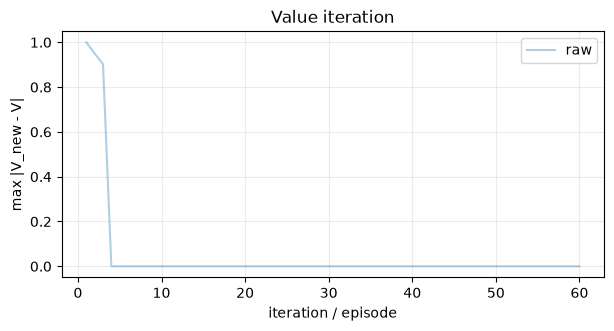

V*: [0.902 0.95  1.    0.   ] greedy actions: [1 1 1 0]


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


gamma = 0.95
# 0--1--2--3(goal)，左右动作；进入 goal 获得 1。
n_states, n_actions = 4, 2
v = np.zeros(n_states)
deltas = []
for _ in range(60):
    q = np.zeros((n_states, n_actions))
    for s in range(n_states - 1):
        left, right = max(0, s - 1), min(n_states - 1, s + 1)
        q[s, 0] = gamma * v[left]
        q[s, 1] = (1.0 if right == n_states - 1 else 0.0) + gamma * v[right]
    new_v = q.max(axis=1)
    deltas.append(np.max(np.abs(new_v - v)))
    v = new_v

plot_curve(deltas, "Value iteration", "max |V_new - V|")
print("V*:", np.round(v, 3), "greedy actions:", q.argmax(axis=1))


### 曲线怎么读

误差传播有明显的逐状态传递阶段，之后残差降到 0。若策略正确但数值有小差异，检查奖励是在离开状态还是进入状态时给出。

### 调参过程：一次只改变一个因素

- 先用确定性小 MDP 手算并和代码逐项对齐。
- 用 tolerance 控制停止，而不是固定迭代次数。
- 再引入随机转移，确认期望对所有 next state 求和。

### 失败案例复盘

- 漏乘转移概率，把期望写成简单求和。
- terminal state 仍 bootstrap，重复计算终点奖励。
- 只检查最终策略，不检查 Bellman residual，隐藏实现错误。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 终止状态不要 bootstrap。
- 同步更新使用旧表计算整张新表；原地更新可能更快，但分析方式不同。
- 价值相近时策略可能因浮点误差改变，调试时同时看 Q 值。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

把到达终点的奖励从 1 改为 0.1，并给留在状态 0 的动作奖励 0.02；观察最优策略如何变化。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

修改奖励后应分别比较‘停留动作的无限小奖励’与‘到终点的一次奖励’。若状态 0 可永远获得 0.02，其价值约为 $0.02/(1-0.9)=0.2$；通往终点的两步价值约为 $0.9\times0.1=0.09$，因此循环可能反而最优。这正说明 reward specification 会改变任务。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- Bellman 方程来自回报的一步递归。
- 期望处理环境随机性，max 处理最优决策。
- value iteration 是不断应用 Bellman backup。
- `max` 给价值，`argmax` 给动作，二者不要混淆。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**为什么状态 0 的价值要到第二轮才出现？`q.max` 和 `q.argmax` 分别返回什么？

<details>
<summary>展开答案</summary>

同步迭代第一轮使用旧的全零价值，所以还看不到两步后的奖励；第二轮才由状态 1 传播回来。`max` 返回最佳数值，`argmax` 返回最佳动作索引。
</details>


## 17. 与前后章节连接

第 6 章在不知道转移概率时，用单条 transition 的 TD target 近似这里的期望，并用网络替代表格。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

policy iteration 在策略评估与策略改进之间交替；异步 value iteration 只更新部分状态，优先 sweeping 会优先更新 Bellman 误差大的状态。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-05) · [← 学习索引](README.md)
